# MUM – zadanie 2

In [1]:
library(tidyverse)
library(car)
library(corrplot)

options(repr.plot.width = 14, repr.plot.height = 8)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


Ładowanie wymaganego pakietu: carData




Dołączanie pakietu: 'car'




Następujący obiekt został zakryty z 'package:dplyr':

    recode




Następujący obiekt został zakryty z 'package:purrr':

    some




corrplot 0.95 loaded



Dane pochodzą z wypożyczalni rowerów miejskich Capital Bikeshare (Waszyngton, lata 2011-2012). Są dwa pliki: day.csv
z danymi dziennymi i hour.csv z danymi godzinowymi. Zmienną objaśnianą jest cnt, czyli liczba wypożyczeń.
Zmienne kategoryczne (pora roku, miesiąc, dzień tygodnia, pogoda itd.) wczytałem jako factor.

In [2]:
day <- read_csv("day.csv", col_types = "iDfffffffnnnniii")
hour <- read_csv("hour.csv", col_types = "iDffffffffnnnniii")

glimpse(day)

Rows: 731
Columns: 16
$ instant    <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, …
$ dteday     <date> 2011-01-01, 2011-01-02, 2011-01-03, 2011-01-04, 2011-01-05…
$ season     <fct> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ yr         <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ mnth       <fct> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ holiday    <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,…
$ weekday    <fct> 6, 0, 1, 2, 3, 4, 5, 6, 0, 1, 2, 3, 4, 5, 6, 0, 1, 2, 3, 4,…
$ workingday <fct> 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1,…
$ weathersit <fct> 2, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 1, 1, 1, 2, 1, 2, 2, 2, 2,…
$ temp       <dbl> 0.3441670, 0.3634780, 0.1963640, 0.2000000, 0.2269570, 0.20…
$ atemp      <dbl> 0.3636250, 0.3537390, 0.1894050, 0.2121220, 0.2292700, 0.23…
$ hum        <dbl> 0.805833, 0.696087, 0.437273, 0.590435, 0.436957, 0.518261,…
$ windspeed  <dbl>

# Wstępna analiza zmiennych
Kolumny pogrupowałem tematycznie:
* czas - instant (numer dnia), dteday (data), season (pora roku: 1 wiosna, 2 lato, 3 jesień, 4 zima), yr (0 = 2011, 1 = 2012),
  mnth (miesiąc), hr (godzina, tylko w hour.csv), holiday (święto), weekday (dzień tygodnia), workingday (dzień roboczy)
* pogoda - weathersit (1 ładnie, 2 mgła/chmury, 3 lekki deszcz lub śnieg, 4 ulewa), temp i atemp (temperatura rzeczywista
  i odczuwalna), hum (wilgotność), windspeed (wiatr) - wszystkie przeskalowane do zakresu 0-1
* wypożyczenia - casual (użytkownicy okazjonalni), registered (zarejestrowani), cnt (wszystkie wypożyczenia)

In [3]:
summary(day)

sum(is.na(day))
sum(is.na(hour))

    instant          dteday           season  yr           mnth     holiday
 Min.   :  1.0   Min.   :2011-01-01   1:181   0:365   1      : 62   0:710  
 1st Qu.:183.5   1st Qu.:2011-07-02   2:184   1:366   3      : 62   1: 21  
 Median :366.0   Median :2012-01-01   3:188           5      : 62          
 Mean   :366.0   Mean   :2012-01-01   4:178           7      : 62          
 3rd Qu.:548.5   3rd Qu.:2012-07-01                   8      : 62          
 Max.   :731.0   Max.   :2012-12-31                   10     : 62          
                                                      (Other):359          
 weekday workingday weathersit      temp             atemp        
 6:105   0:231      2:247      Min.   :0.05913   Min.   :0.07907  
 0:105   1:500      1:463      1st Qu.:0.33708   1st Qu.:0.33784  
 1:105              3: 21      Median :0.49833   Median :0.48673  
 2:104                         Mean   :0.49538   Mean   :0.47435  
 3:104                         3rd Qu.:0.65542   3rd Qu.:

[1] 0

[1] 0

Braków danych nie ma. Zwróciłem uwagę na dwie rzeczy:
* hum ma minimum 0, czyli wilgotność 0%, co jest niemożliwe. Sprawdzam, którego dnia to wystąpiło.
* cnt ma minimum 22 przy medianie 4548.

In [4]:
day %>%
  filter(hum == 0 | cnt < 100) %>%
  select(dteday, weathersit, hum, cnt)

dteday,weathersit,hum,cnt
<date>,<fct>,<dbl>,<int>
2011-03-10,3,0.00,623
2012-10-29,3,0.88,22


Wilgotność 0 jest tylko 10.03.2011, więc traktuję to jako błąd pomiaru i wstawiam medianę. Dzień z 22 wypożyczeniami
to 29.10.2012, czyli huragan Sandy. To prawdziwa obserwacja, więc ją zostawiam.

In [5]:
day <- day %>%
  mutate(hum = ifelse(hum == 0, median(hum), hum))

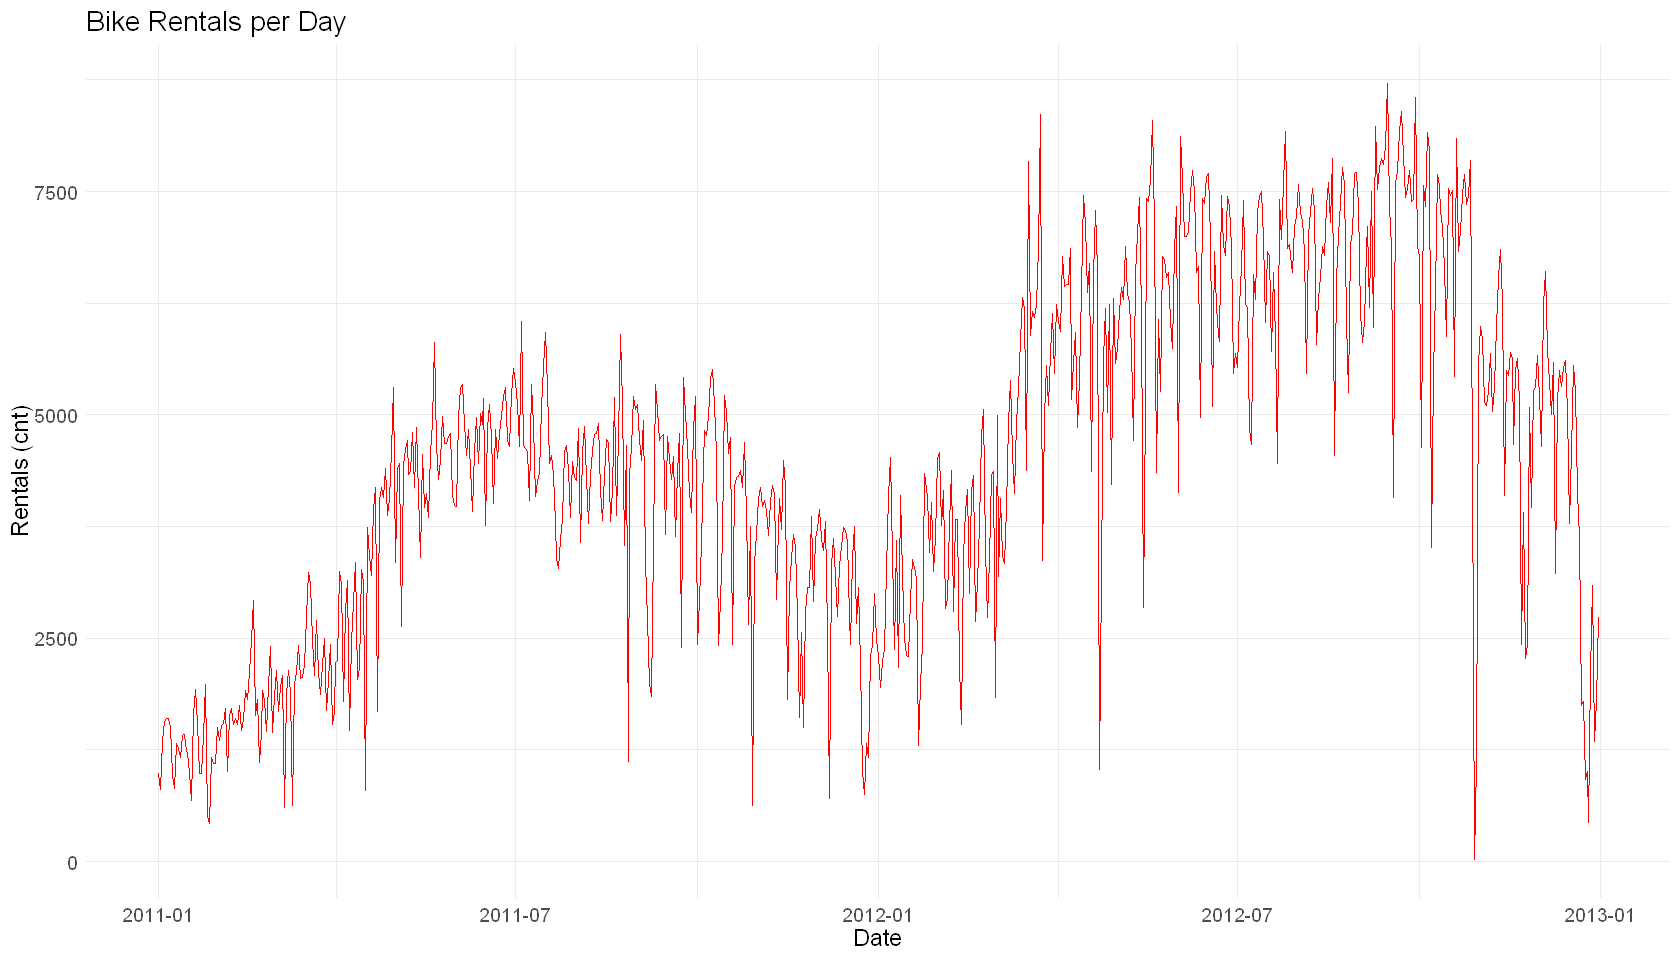

In [6]:
day %>%
  ggplot() +
  geom_line(mapping = aes(x = dteday, y = cnt), color = "red") +
  labs(title = "Bike Rentals per Day", x = "Date", y = "Rentals (cnt)") +
  theme_minimal() +
  theme(text = element_text(size = 14))

W 2012 roku wypożyczeń było wyraźnie więcej (średnio ok. 5600 dziennie, w 2011 ok. 3400). W obu latach widać sezon:
dużo wypożyczeń latem, mało zimą.

# Korelacje

[1] TRUE

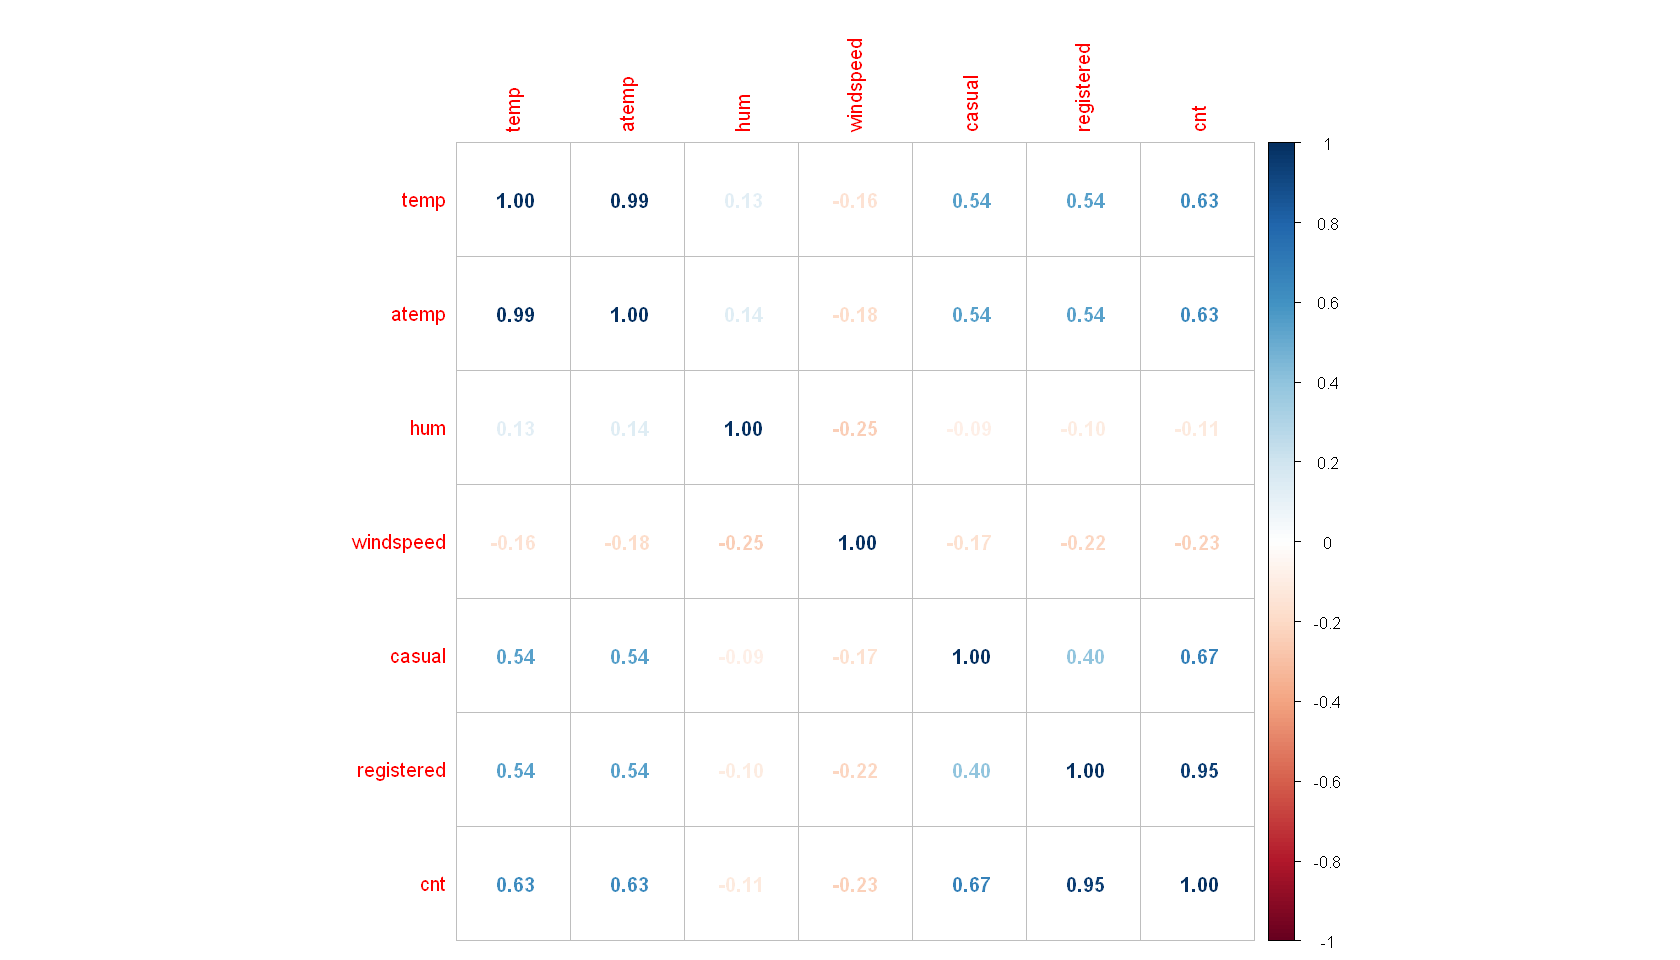

In [7]:
# czy cnt to suma casual i registered
all(day$cnt == day$casual + day$registered)

kor <- cor(select(day, temp, atemp, hum, windspeed, casual, registered, cnt))
corrplot(kor, method = "number")

* cnt to dokładnie suma casual i registered, więc tych dwóch zmiennych nie biorę do modelu (zdradzałyby wynik).
* temp i atemp są prawie identyczne (r = 0,99), więc zostawiam tylko temp.
* Z cnt najmocniej skorelowana jest temperatura (r = 0,63), a hum i windspeed słabo i ujemnie.

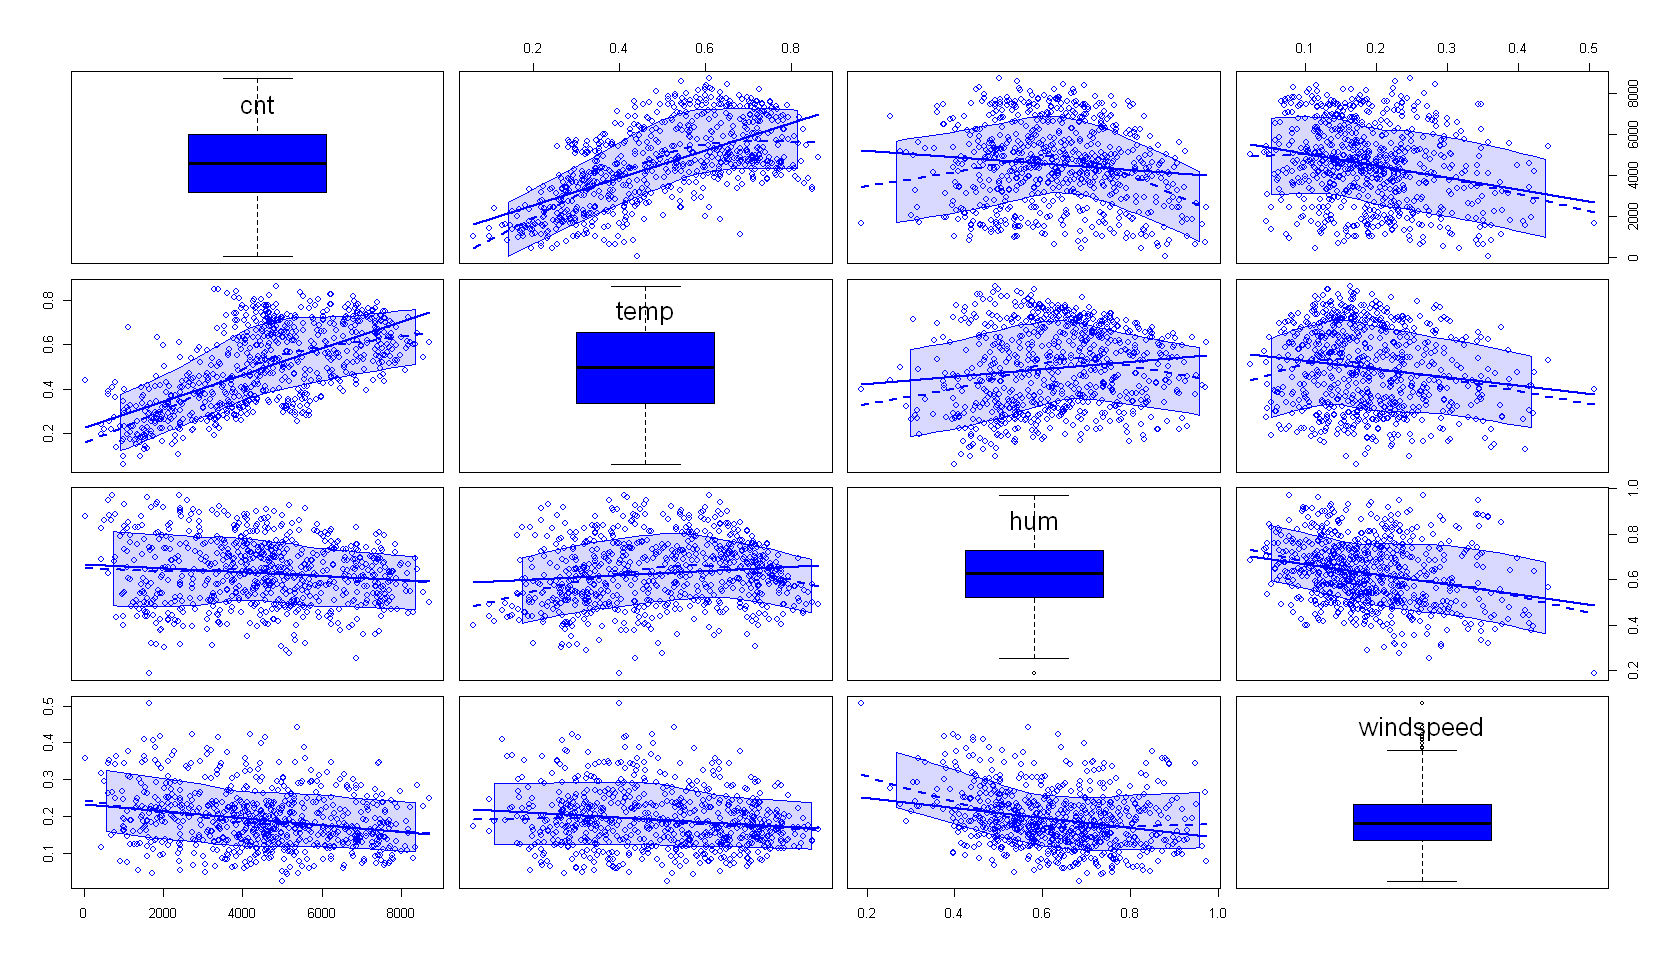

In [8]:
scatterplotMatrix(~ cnt + temp + hum + windspeed, data = day, diagonal = list(method = "boxplot"))

In [9]:
# współczynnik korelacji r między cnt a każdą zmienną
day %>%
  summarize(across(c(temp, hum, windspeed), ~ round(cor(cnt, .x), 2)))

temp,hum,windspeed
<dbl>,<dbl>,<dbl>
0.63,-0.11,-0.23


Macierz pokazuje zależności między każdą parą zmiennych (linia ciągła to prosta regresji, przerywana to krzywa wygładzająca),
a na przekątnej rozkład każdej zmiennej. Najważniejszy jest pierwszy wiersz, bo cnt to zmienna objaśniana. Na tych wykresach
cnt jest na osi Y, więc widać, jak liczba wypożyczeń zależy od każdej z pozostałych zmiennych. Siłę tych zależności
pokazuje współczynnik korelacji r z tabeli powyżej:
* temp (r = 0,63) - wyraźny wzrost, ale krzywa odgina się od prostej przy wysokich temperaturach
* hum (r = -0,11) - prawie płasko, zależność słaba
* windspeed (r = -0,23) - lekki spadek, przy silnym wietrze wypożyczeń jest mniej

Między samymi zmiennymi objaśniającymi zależności są słabe, więc nie dublują informacji.
Dlatego dokładniej przyglądam się tylko zależności cnt od temp. Ma zdecydowanie największe r, a na wykresie jako jedyna
wyraźnie nie wygląda na liniową (r mierzy tylko zależność liniową, więc kształt trzeba sprawdzić na wykresie).

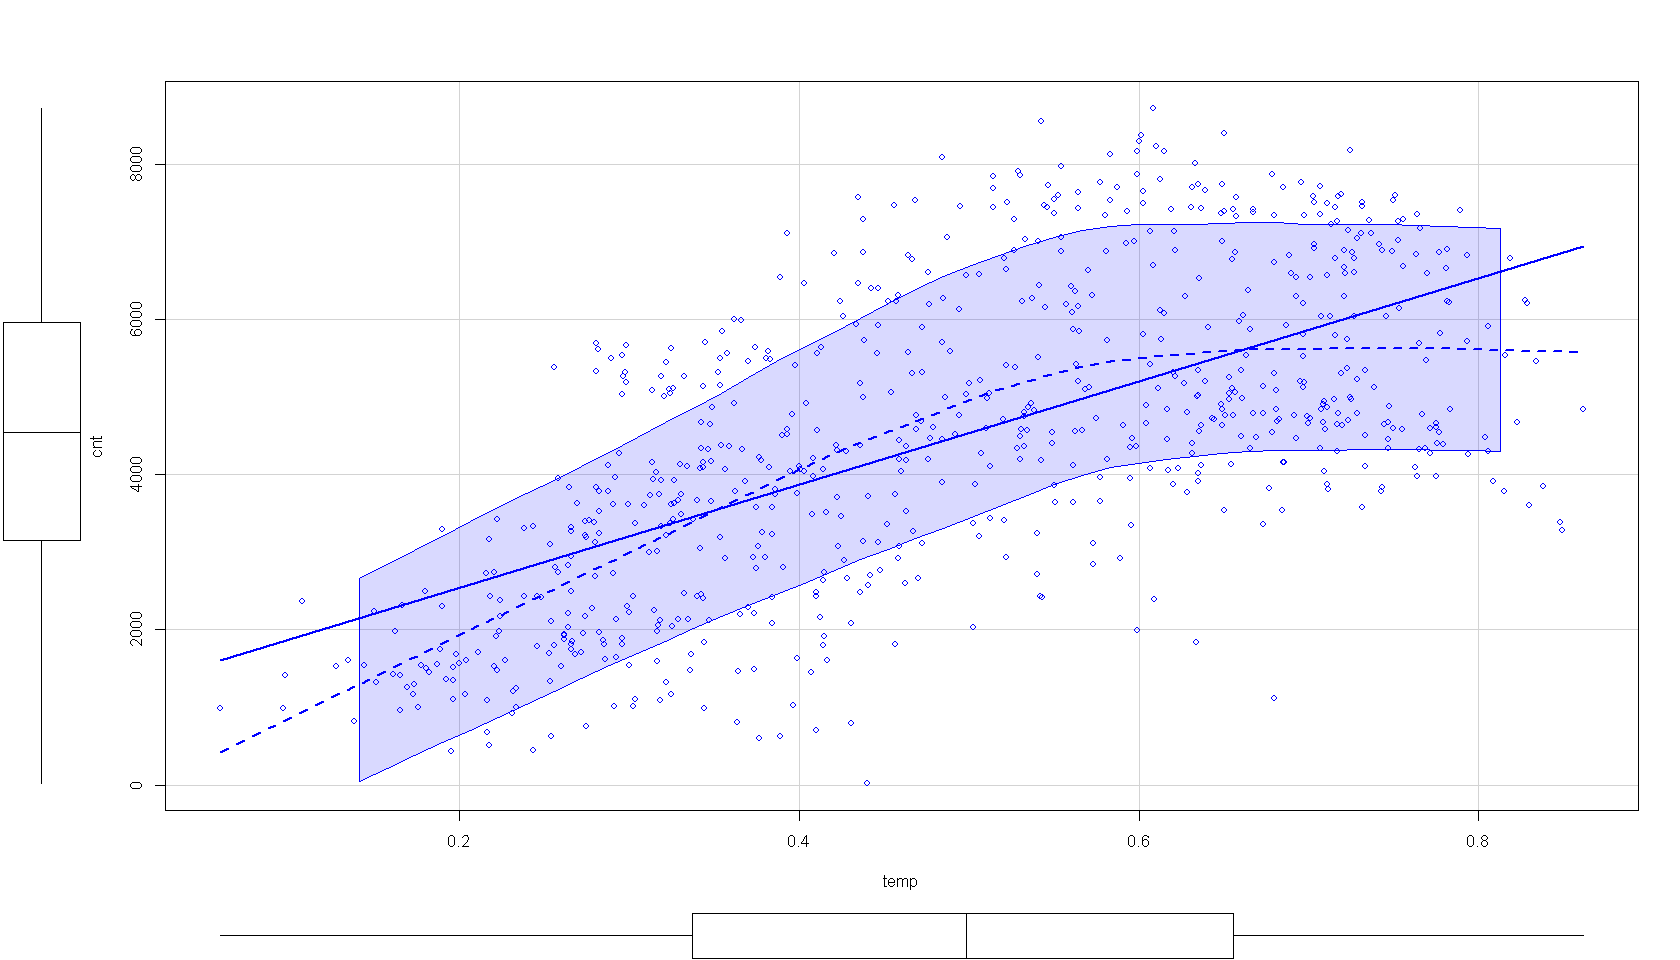

In [10]:
scatterplot(cnt ~ temp, data = day, boxplots = "xy")

Na wykresie cnt od temp linia przerywana rośnie stromo do temperatury ok. 0,6, potem się spłaszcza, a przy największych
upałach lekko spada. Prosta regresji tego nie oddaje: przy niskich i bardzo wysokich temperaturach zawyża liczbę
wypożyczeń, a przy średnich ją zaniża. Dlatego później spróbuję dodać do modelu temp^2.

[1] "442" "668"

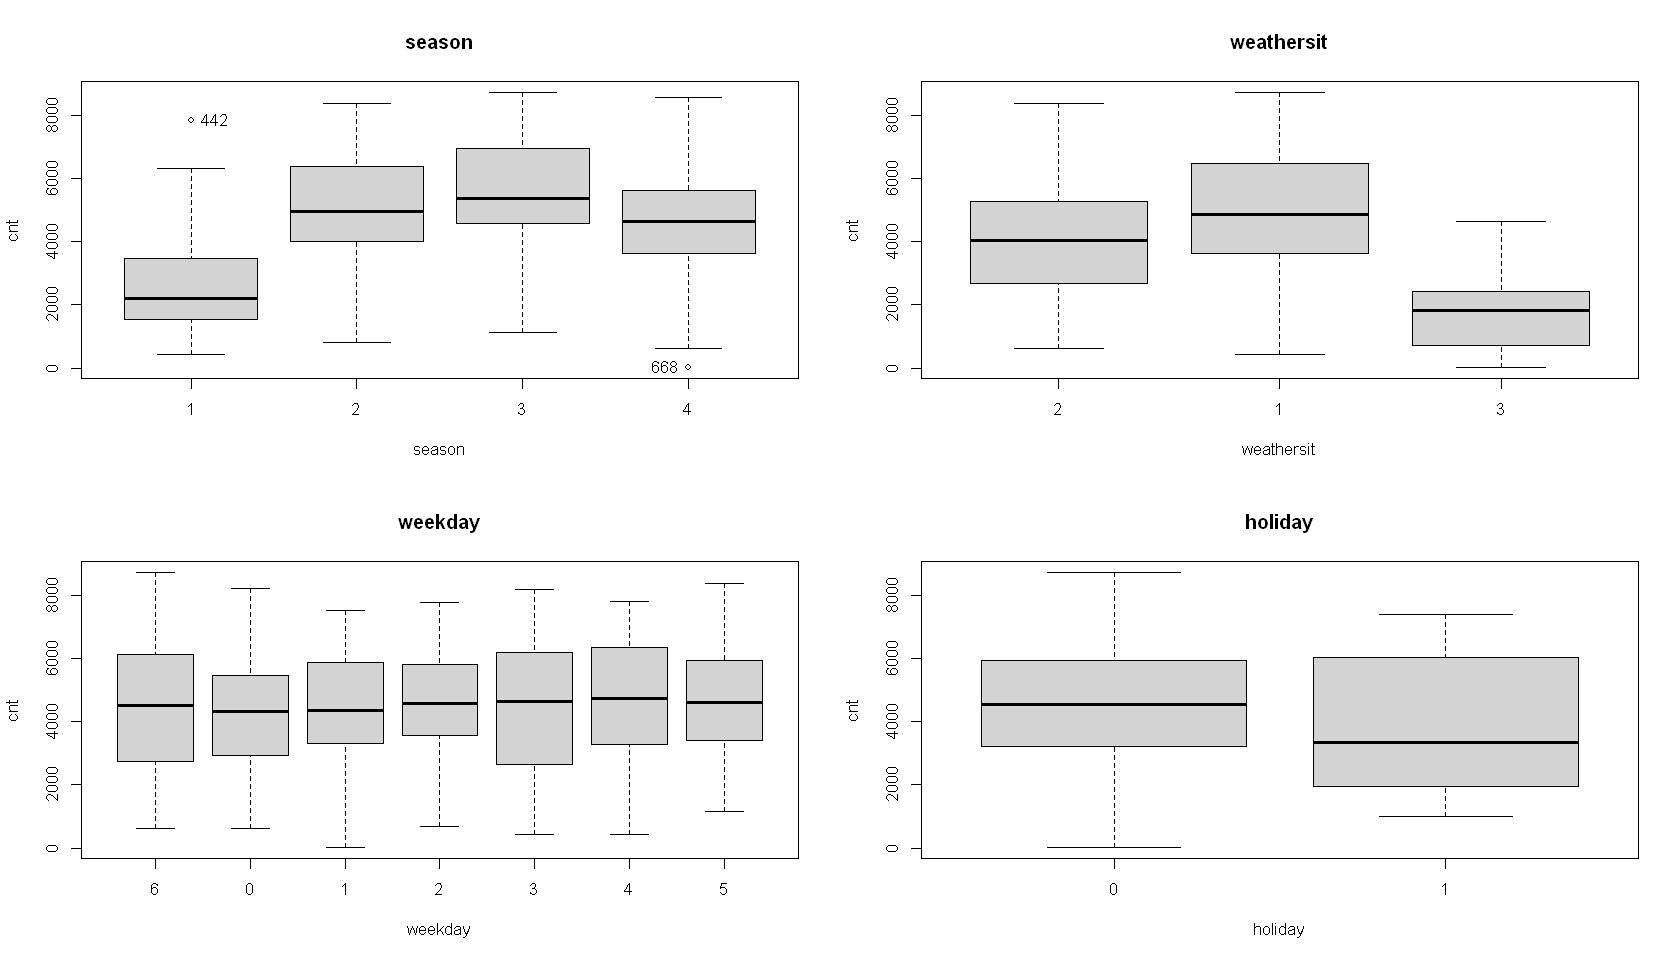

In [11]:
par(mfrow = c(2, 2))
Boxplot(cnt ~ season, data = day, main = "season")
Boxplot(cnt ~ weathersit, data = day, main = "weathersit")
Boxplot(cnt ~ weekday, data = day, main = "weekday")
Boxplot(cnt ~ holiday, data = day, main = "holiday")

* season - najmniej wypożyczeń wiosną (mediana ok. 2200, bo to głównie styczeń-marzec), najwięcej latem i jesienią (ok. 4900-5400)
* weathersit - im gorsza pogoda, tym mniej wypożyczeń (mediana 4844 przy ładnej pogodzie i 1817 przy deszczu)
* weekday - mediany w poszczególne dni są podobne
* holiday - w święta wypożyczeń jest mniej (mediana 3351 vs 4558), chociaż świąt jest tylko 21

In [12]:
table(day$workingday, day$weekday)

# czy workingday = poniedziałek-piątek i nie święto
all(day$workingday == ifelse(day$weekday %in% 1:5 & day$holiday == 0, 1, 0))

   
      6   0   1   2   3   4   5
  0 105 105  15   1   1   2   2
  1   0   0  90 103 103 102 102

[1] TRUE

W tabeli wiersze to workingday (0 wolny, 1 roboczy), a kolumny dni tygodnia (6 sobota, 0 niedziela, 1-5 poniedziałek-piątek).
Weekendy zawsze mają 0, a w dni powszednie 0 pojawia się tylko 21 razy, czyli dokładnie w święta. Sprawdzenie zwraca TRUE,
więc workingday wynika wprost z weekday i holiday. W modelu z tymi trzema zmiennymi jednocześnie R nie policzyłby
współczynnika dla workingday (NA), dlatego jej nie biorę. instant i dteday też pomijam, bo trend w czasie opisują już yr i mnth.

# Model liniowy (day)
Zaczynam od modelu ze wszystkimi zmiennymi, które zostały po analizie.

In [13]:
day.model1 <- lm(cnt ~ season + yr + mnth + holiday + weekday + weathersit + temp + hum + windspeed, data = day)
summary(day.model1)

Anova(day.model1)


Call:
lm(formula = cnt ~ season + yr + mnth + holiday + weekday + weathersit + 
    temp + hum + windspeed, data = day)

Residuals:
    Min      1Q  Median      3Q     Max 
-3936.1  -350.0    73.4   448.9  2900.9 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1594.565    272.357   5.855 7.33e-09 ***
season2       870.980    179.205   4.860 1.45e-06 ***
season3       815.115    213.032   3.826 0.000142 ***
season4      1572.333    180.864   8.693  < 2e-16 ***
yr1          2012.882     58.283  34.536  < 2e-16 ***
mnth2         133.314    143.624   0.928 0.353615    
mnth3         560.818    164.974   3.399 0.000713 ***
mnth4         465.078    247.092   1.882 0.060220 .  
mnth5         737.092    267.069   2.760 0.005932 ** 
mnth6         489.903    281.276   1.742 0.081995 .  
mnth7           5.168    312.987   0.017 0.986829    
mnth8         407.503    301.037   1.354 0.176278    
mnth9         990.400    264.373   3.746 0.000194 ***
mnth10        

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
season,51544266,3,29.075676,9.936274e-18
yr,704830837,1,1192.767009,1.386574e-153
mnth,57478543,11,8.842678,7.810816e-15
holiday,6643771,1,11.243082,8.420380e-04
weekday,14850625,6,4.188555,3.778059e-04
weathersit,54701173,2,46.284691,1.307551e-19
temp,71205383,1,120.499029,5.512458e-26
hum,16851867,1,28.517979,1.254650e-07
windspeed,31511730,1,53.326487,7.671710e-13


Model wyjaśnia ok. 84% zmienności cnt (skorygowane R^2 = 0,843). Według tablicy ANOVA wszystkie zmienne są istotne (p < 0,05).
Żeby sprawdzić redukcję, usuwam po kolei pojedyncze zmienne i patrzę na skorygowane R^2.

In [14]:
modele <- list(
  "pełny"         = day.model1,
  "bez mnth"      = update(day.model1, . ~ . - mnth),
  "bez season"    = update(day.model1, . ~ . - season),
  "bez weekday"   = update(day.model1, . ~ . - weekday),
  "bez holiday"   = update(day.model1, . ~ . - holiday),
  "bez hum"       = update(day.model1, . ~ . - hum),
  "bez windspeed" = update(day.model1, . ~ . - windspeed)
)
sapply(modele, function(m) round(summary(m)$adj.r.squared, 4))

pełny      bez mnth    bez season   bez weekday   bez holiday 
       0.8425        0.8235        0.8238        0.8383        0.8402 
      bez hum bez windspeed 
       0.8364        0.8308

Usunięcie każdej zmiennej obniża skorygowane R^2 (najbardziej mnth i season, do ok. 0,824), więc w modelu liniowym
zostawiam wszystkie zmienne.

# Model nieliniowy (day)
Sprawdzam dwa podejścia: dodanie temp^2 (żeby uwzględnić spadek wypożyczeń w upały) i logarytmowanie zmiennych jak na zajęciach.

In [15]:
day.model2 <- lm(cnt ~ season + yr + mnth + holiday + weekday + weathersit + temp + I(temp^2) + hum + windspeed, data = day)
summary(day.model2)

Anova(day.model2)


Call:
lm(formula = cnt ~ season + yr + mnth + holiday + weekday + weathersit + 
    temp + I(temp^2) + hum + windspeed, data = day)

Residuals:
    Min      1Q  Median      3Q     Max 
-3682.3  -346.5    41.3   433.5  2769.8 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)    -97.72     301.81  -0.324  0.74619    
season2        806.98     167.12   4.829 1.69e-06 ***
season3       1016.61     199.49   5.096 4.46e-07 ***
season4       1528.21     168.61   9.064  < 2e-16 ***
yr1           1953.92      54.61  35.777  < 2e-16 ***
mnth2         -176.67     137.15  -1.288  0.19813    
mnth3           71.41     160.84   0.444  0.65717    
mnth4          -86.27     236.34  -0.365  0.71522    
mnth5          419.39     250.78   1.672  0.09490 .  
mnth6          453.93     262.16   1.732  0.08380 .  
mnth7          253.93     292.68   0.868  0.38590    
mnth8          329.71     280.65   1.175  0.24047    
mnth9          539.22     250.20   2.155  0.03149 *  
mn

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
season,44917181,3,29.172410,8.774148e-18
yr,656938908,1,1279.988478,2.264947e-160
mnth,32621216,11,5.778146,5.470753e-09
holiday,4404829,1,8.582427,3.504316e-03
weekday,15594015,6,5.063931,4.236622e-05
weathersit,53845217,2,52.456367,5.864090e-22
temp,94580869,1,184.282619,1.922270e-37
I(temp^2),55124148,1,107.404621,1.627115e-23
hum,24740201,1,48.204136,8.758714e-12


temp^2 jest istotna, a skorygowane R^2 wzrosło z 0,843 do 0,863. Ujemny współczynnik przy temp^2 potwierdza, że od pewnej
temperatury (ok. 0,63, czyli ok. 26°C) wypożyczeń zaczyna ubywać.

In [16]:
day$log.cnt <- log(day$cnt)
day$log.temp <- log(day$temp)
day$log.hum <- log(day$hum)
day$log.windspeed <- log(day$windspeed)

day.model3 <- lm(log.cnt ~ season + yr + mnth + holiday + weekday + weathersit + log.temp + log.hum + log.windspeed, data = day)
summary(day.model3)

Anova(day.model3)


Call:
lm(formula = log.cnt ~ season + yr + mnth + holiday + weekday + 
    weathersit + log.temp + log.hum + log.windspeed, data = day)

Residuals:
    Min      1Q  Median      3Q     Max 
-4.3976 -0.0839  0.0386  0.1343  0.8879 

Coefficients:
               Estimate Std. Error t value Pr(>|t|)    
(Intercept)    7.891340   0.106800  73.889  < 2e-16 ***
season2        0.290815   0.066145   4.397 1.27e-05 ***
season3        0.358204   0.078370   4.571 5.74e-06 ***
season4        0.554106   0.066795   8.296 5.50e-16 ***
yr1            0.450808   0.021557  20.912  < 2e-16 ***
mnth2          0.060530   0.054165   1.118 0.264154    
mnth3          0.088225   0.063321   1.393 0.163966    
mnth4          0.010862   0.092986   0.117 0.907043    
mnth5          0.081083   0.098120   0.826 0.408877    
mnth6         -0.030908   0.100341  -0.308 0.758152    
mnth7         -0.168994   0.110683  -1.527 0.127255    
mnth8         -0.114840   0.108558  -1.058 0.290478    
mnth9          0.023803   

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
season,5.9317037,3,24.529044,4.196639e-15
yr,35.2517278,1,437.323511,6.996212e-76
mnth,2.3789354,11,2.682949,2.195026e-03
holiday,0.7836933,1,9.722289,1.894736e-03
weekday,0.9970868,6,2.061599,5.566521e-02
weathersit,14.9861421,2,92.957036,1.515596e-36
log.temp,12.0795783,1,149.856019,2.264889e-31
log.hum,1.5910095,1,19.737638,1.031689e-05
log.windspeed,2.5890621,1,32.119213,2.116277e-08


W modelu logarytmicznym weekday jest na granicy istotności (p = 0,056). Sprawdzam, co się stanie po jej usunięciu.

In [17]:
day.model4 <- update(day.model3, . ~ . - weekday)

round(c(z_weekday = summary(day.model3)$adj.r.squared, bez_weekday = summary(day.model4)$adj.r.squared), 4)

z_weekday bez_weekday 
     0.7631      0.7610

Bez weekday skorygowane R^2 minimalnie spada (0,763 -> 0,761), więc zostaję przy pełnym modelu logarytmicznym.

R^2 modelu logarytmicznego jest liczone dla log(cnt), więc nie można go wprost porównać z modelami liniowymi.
Dlatego dla wszystkich modeli liczę R^2 i RMSE (średni błąd w liczbie wypożyczeń) na oryginalnej skali cnt.

In [18]:
ocena <- function(model, y, log = FALSE) {
  pred <- if (log) exp(fitted(model)) else fitted(model)
  c(R2 = round(1 - sum((y - pred)^2) / sum((y - mean(y))^2), 3),
    RMSE = round(sqrt(mean((y - pred)^2))))
}

rbind("liniowy"          = ocena(day.model1, day$cnt),
      "liniowy + temp^2" = ocena(day.model2, day$cnt),
      "logarytmiczny"    = ocena(day.model3, day$cnt, log = TRUE))

,R2,RMSE
liniowy,0.848,754
liniowy + temp^2,0.868,702
logarytmiczny,0.822,816


Najlepszy dla danych dziennych jest model liniowy z temp^2: R^2 = 0,868, a średni błąd ok. 700 wypożyczeń dziennie.
Model logarytmiczny wypada najgorzej (RMSE ok. 816). Jedną z przyczyn jest dzień huraganu: po zlogarytmowaniu
22 wypożyczenia bardzo odstają od reszty i mocniej wpływają na model.

# Dane godzinowe (hour)

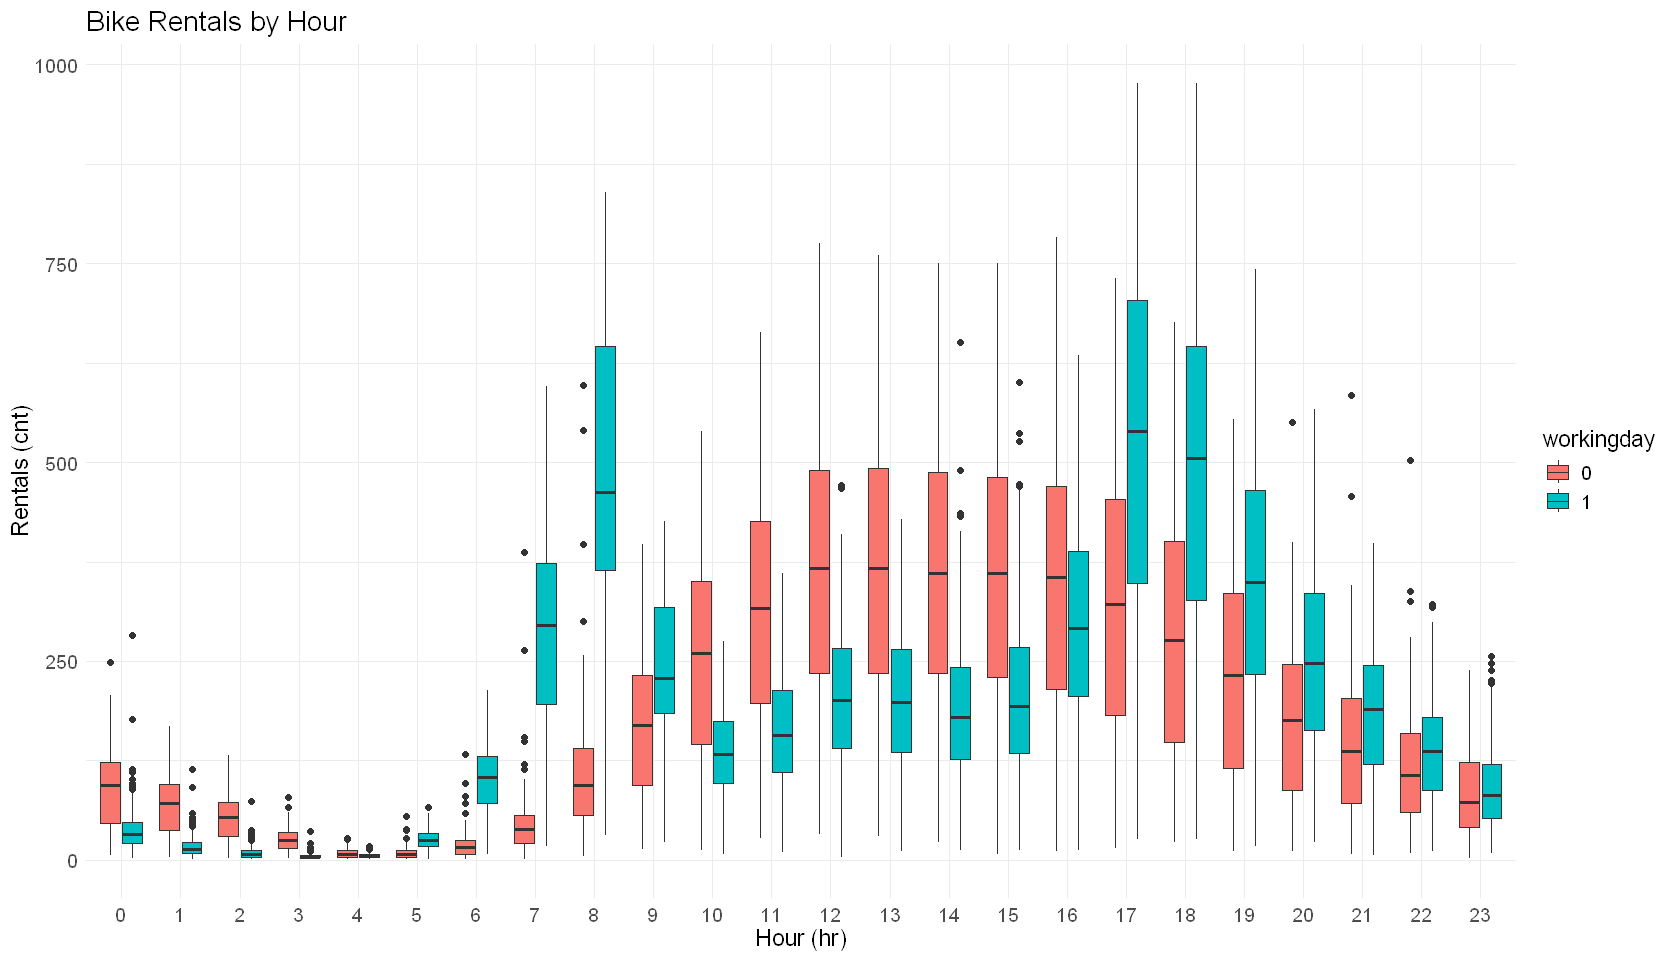

In [19]:
hour %>%
  ggplot() +
  geom_boxplot(mapping = aes(x = hr, y = cnt, fill = workingday)) +
  labs(title = "Bike Rentals by Hour", x = "Hour (hr)", y = "Rentals (cnt)") +
  theme_minimal() +
  theme(text = element_text(size = 14))

Najważniejsza w danych godzinowych jest godzina, ale jej wpływ zależy od tego, czy jest dzień roboczy:
* w dni robocze są dwa szczyty: rano o 8 (mediana 463) i po południu o 17-18 (ok. 500-540), czyli dojazdy do pracy i szkoły,
* w weekendy i święta jest jeden szczyt w środku dnia (ok. 360 między 12 a 15).

Dlatego oprócz zwykłego modelu sprawdzam model z interakcją hr * workingday. Rozkład cnt jest prawostronnie skośny
(średnia 189, mediana 142), więc używam log(cnt). weekday pomijam w modelu z interakcją, bo razem z workingday i holiday
dublowałby informację.

In [20]:
hour$log.cnt <- log(hour$cnt)

hour.model1 <- lm(cnt ~ season + yr + mnth + hr + holiday + weekday + weathersit + temp + hum + windspeed, data = hour)
hour.model2 <- lm(log.cnt ~ season + yr + mnth + hr + holiday + weekday + weathersit + temp + hum + windspeed, data = hour)
hour.model3 <- lm(log.cnt ~ season + yr + mnth + hr * workingday + holiday + weathersit + temp + hum + windspeed, data = hour)

Anova(hour.model3)

rbind("liniowy"                       = ocena(hour.model1, hour$cnt),
      "logarytmiczny"                 = ocena(hour.model2, hour$cnt, log = TRUE),
      "logarytmiczny + hr*workingday" = ocena(hour.model3, hour$cnt, log = TRUE))

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
season,168.422435,3,343.30741,1.420491e-216
yr,963.173088,1,5889.91226,0.000000e+00
mnth,58.534635,11,32.54054,2.858314e-69
hr,19421.893482,23,5163.78579,0.000000e+00
workingday,9.904171,1,60.56512,7.517815e-15
holiday,19.248670,1,117.70779,2.460270e-27
weathersit,374.282219,3,762.92602,0.000000e+00
temp,236.956622,1,1449.01652,1.469744e-304
hum,17.628943,1,107.80298,3.519690e-25


,R2,RMSE
liniowy,0.686,102
logarytmiczny,0.705,99
logarytmiczny + hr*workingday,0.869,66


Wszystkie zmienne w modelu z interakcją są istotne. Sam logarytm poprawia wynik niewiele (RMSE 102 -> 99), ale dodanie
interakcji hr * workingday daje duży skok: R^2 = 0,869, a średni błąd spada do ok. 66 wypożyczeń na godzinę.

# Wybór najlepszego modelu
* dane dzienne - model liniowy z temp^2: cnt ~ season + yr + mnth + holiday + weekday + weathersit + temp + temp^2 + hum + windspeed
  (R^2 = 0,868, RMSE ok. 700)
* dane godzinowe - model logarytmiczny z interakcją: log(cnt) ~ season + yr + mnth + hr * workingday + holiday + weathersit + temp + hum + windspeed
  (R^2 = 0,869, RMSE ok. 66)